<a href="https://colab.research.google.com/github/YousefHanna20/Student-Performance-EDA/blob/main/Student_Performance_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Student Performance in Exams
##Author: Yousef Hanna


##Project Overview

##Load and Inspect Data

In [1]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
#loading the data set
fpath = "/content/drive/MyDrive/Colab Notebooks/StudentsPerformance.csv"
df = pd.read_csv(fpath)
#Preview the first rows
print(df.head())
print('\n')
#Reporting the  number of rows and columns
print(df.shape)
#Checking the data type of each column
print('\n')
print(df.dtypes)




   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


(1000, 8)


gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          

###-The dataset has 1000 rows/observations and 8 columns/features.
###-The dataset contains these 8 columns:
###  1) gender : The student's gender.
###  2) race/ethnicity: The student's group, represented by categories A–E.
### 3) parental level of education: The highest education level attained by the student's parents.
### 4) lunch: The student's lunch category (standard or free/reduced).
### 5) test preparation course: Whether the student completed a test preparation course.
###6) math score: The student's mathematics exam score.
###7) reading score: The student's reading exam score.
###8) writing score: The student's writing exam score.

##Clean Data

In [2]:
#Checking for missing values
null_sums = df.isna().sum()
print(null_sums)
#Check for duplicates
duplicates = df.duplicated(keep =False).sum()
print('\n')
print( "Number of duplicated rows = " , duplicates)
#Checking for inconsistent values
string_cols = df.select_dtypes('object').columns
for col in string_cols:
  print(f"Value counts for {col} :")
  print(df[col].value_counts())
  print('\n')
#Checking for impossible values inside score columns
num_cols = df.select_dtypes('int64').columns
for col in num_cols:
  print(f"Description for  {col} :")
  print(df[col].describe())
  print('\n')
#Checking the data types
print(df.dtypes)
#Checking for Outliers
for col in num_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
  print(f"Outliers for {col} :")
  print(len(outliers))
  print('\n')

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


Number of duplicated rows =  0
Value counts for gender :
gender
female    518
male      482
Name: count, dtype: int64


Value counts for race/ethnicity :
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64


Value counts for parental level of education :
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64


Value counts for lunch :
lunch
standard        645
free/reduced    355
Name: count, dtype: int64


Value counts for test preparation course :
test preparation course
none         642
complet

In [3]:
#Renaming columns
df.columns =df.columns.str.replace(' ', "_" ).str.replace("/" , "_")
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


<Axes: >

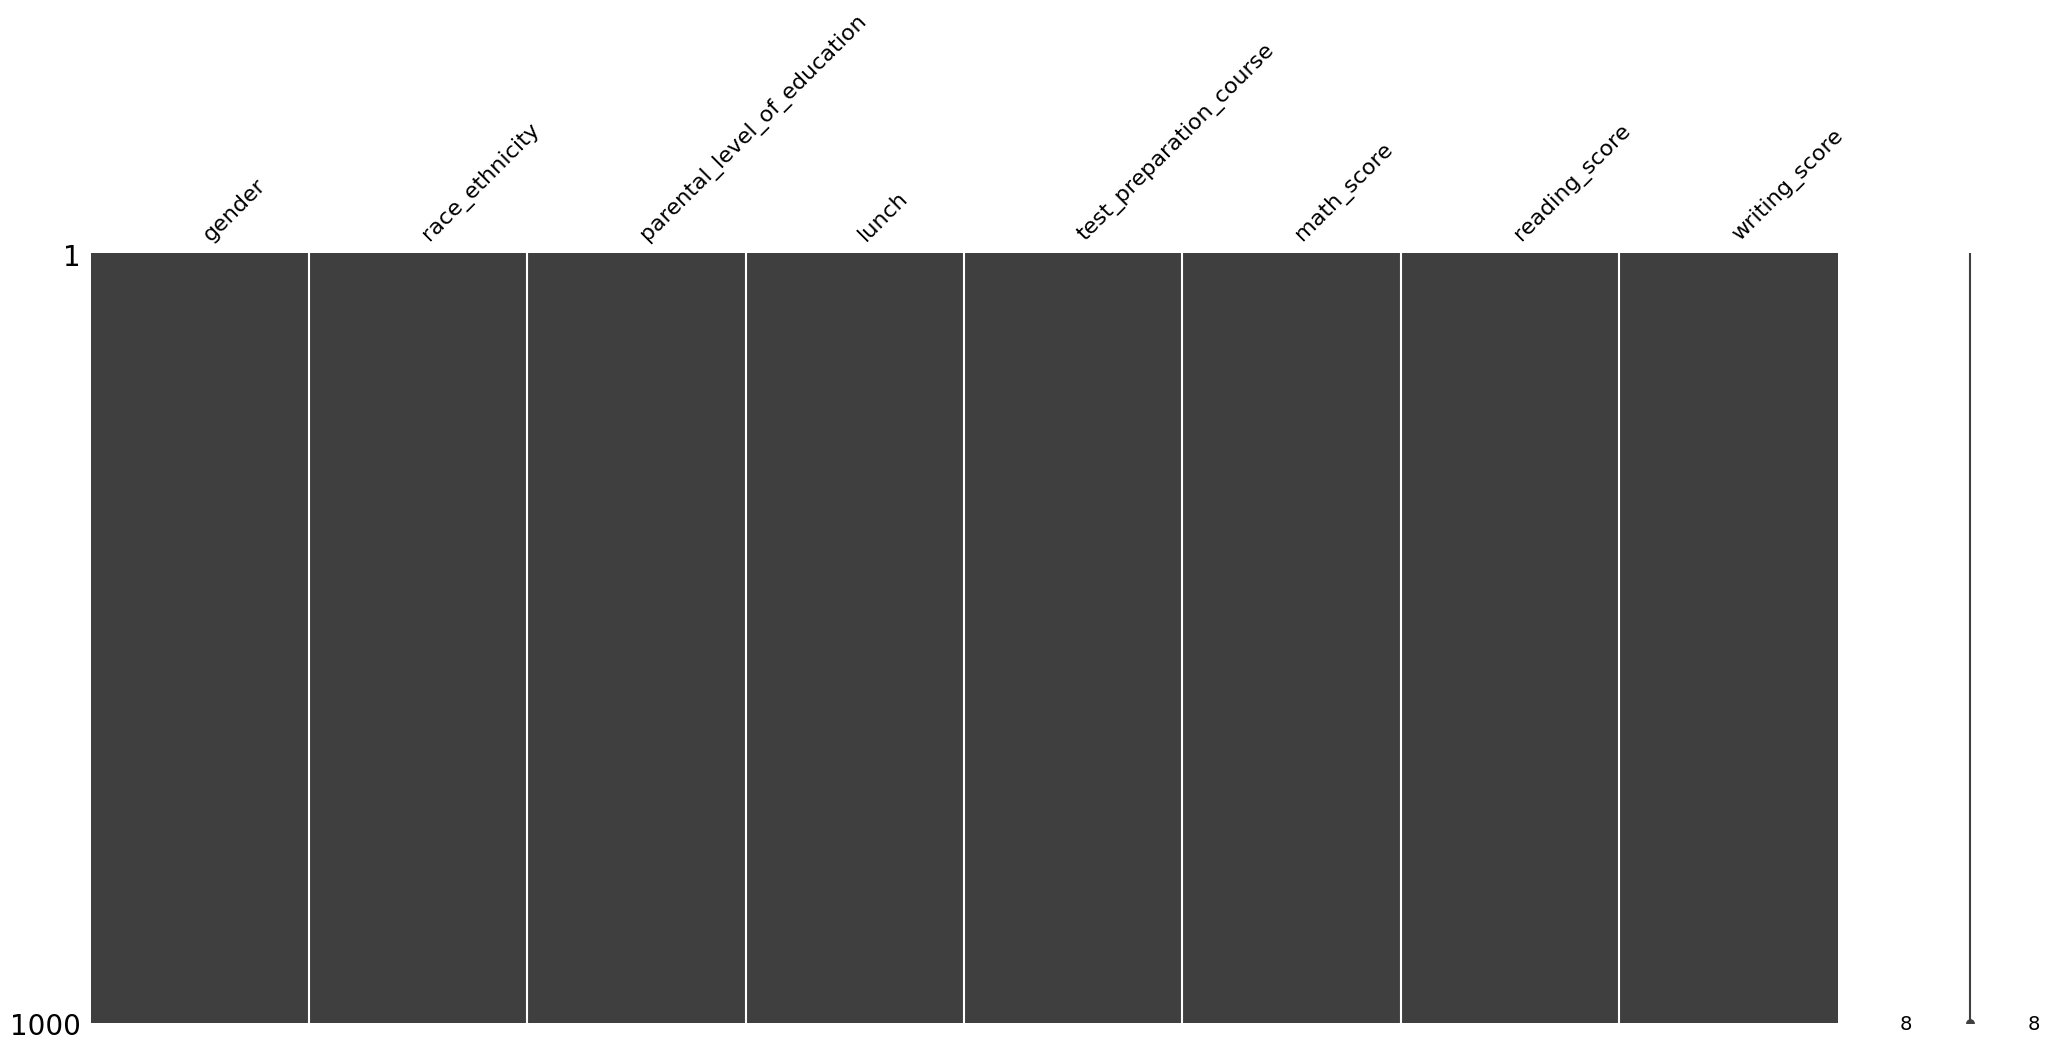

In [4]:
#Using matrix plot to confirm there is no missing values exist
import missingno as msno
msno.matrix(df)

##Analysis Questions:
**Q1:Which columns are numerical, and which are categorical?**

 The dataset contains three numerical columns: math_score, reading_score, and writing_score. The remaining five columns are categorical: gender, race_ethnicity, parental_level_of_education, lunch, and test_preparation_course.

 **Q2: Did you find missing values, duplicates, or inconsistent categories?**

 No missing values or duplicate rows were found in the dataset. Additionally, the categorical columns appear to contain consistent values, with no obvious spelling errors or formatting inconsistencies. Therefore, no major cleaning was required.

 **Q3: Are there outliers in the scores? Should they removed, or Kept? Why?**

 The score columns may contain statistical outliers, particularly unusually very low or high scores. However, these values should be kept because they fall within the valid range of 0 to 100 and may represent genuine student performance. Removing them could lead to biased results.

###Conclusion for data cleaning :
The Student Performance dataset contains 1,000 rows and 8 columns, including 5 categorical and 3 numerical variables.

The data inspection revealed no missing values, duplicate rows, or obvious inconsistencies in the categorical columns. All columns have appropriate data types, and all exam scores fall within the valid range of 0 to 100.

Using the IQR method, I identified 8 outliers in math scores, 6 in reading scores, and 5 in writing scores. These outliers were retained because they may represent genuine student performance.

Finally, the column names were standardized by replacing spaces and special characters with underscores.

Overall, the dataset is clean and ready for further exploratory data analysis.

##Data Preparation

In [5]:
#Separate categorical and numerical columns
num_cols = df.select_dtypes('int64').columns
cat_cols = df.select_dtypes('object').columns
print("Numerical Features:", num_cols)
print('\n')
print("Categorical Features:", cat_cols)

Numerical Features: Index(['math_score', 'reading_score', 'writing_score'], dtype='object')


Categorical Features: Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course'],
      dtype='object')


In [6]:
#Creating a derived columns
#First: the sum of the three scores
df['total_score'] = df[num_cols].sum(axis = 1)
#Second: the mean of the three scores
df['average_score'] = df[num_cols].sum(axis = 1) / 3
#Third: passing the math score
df['pass_math'] = df['math_score'] >= 50
#Fourth: Performance level
df['performance_level'] = pd.cut(
    df['average_score'],
    bins=[-1, 50, 75, 101],
    labels=['Low', 'Medium', 'High'],
    right=False
)


In [7]:
#Checking the shape, data types and preview
print(df.shape)
print('\n')
print(df.dtypes)
print('\n')
df.head()


(1000, 12)


gender                           object
race_ethnicity                   object
parental_level_of_education      object
lunch                            object
test_preparation_course          object
math_score                        int64
reading_score                     int64
writing_score                     int64
total_score                       int64
average_score                   float64
pass_math                          bool
performance_level              category
dtype: object




,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score,pass_math,performance_level
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667,True,Medium
1,female,group C,some college,standard,completed,69,90,88,247,82.333333,True,High
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667,True,High
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333,False,Low
4,male,group C,some college,standard,none,76,78,75,229,76.333333,True,High


### Data Preparation Explanation

The dataset contains three numerical features (math_score, reading_score, and writing_score) and five categorical features (gender, race_ethnicity, parental_level_of_education, lunch, and test_preparation_course).

To make the analysis more informative, I created four derived columns:

1. **total_score:** Calculates the sum of the math, reading, and writing scores to represent each student's overall score.
2. **average_score:** Calculates the mean of the three exam scores to measure overall academic performance.
3. **pass_math:** Indicates whether a student passed mathematics using a score of 50 as the passing threshold.
4. **performance_level:** Categorizes students into Low (below 50), Medium (50–74.99), and High (75–100) based on their average scores.

These new features will help analyze student performance, compare different groups, and create more meaningful visualizations.

After data preparation, the dataset contains 1,000 rows and 12 columns, with appropriate data types for the newly created features.

##Statistical Analysis: Math Score

In [8]:
#Calculating the descriptive analysis of math score

math = df['math_score']

import pandas as pd

math_stats = pd.DataFrame({
    'Statistic': [
        'Mean', 'Median', 'Mode', 'Variance',
        'Standard Deviation', 'Minimum', 'Maximum',
        'Q1 (25%)', 'Q2 (50%)', 'Q3 (75%)',
        'Skewness', 'Kurtosis'
    ],
    'Value': [
        math.mean(), math.median(), math.mode()[0],
        math.var(), math.std(),
        math.min(), math.max(),
        math.quantile(0.25),
        math.quantile(0.50),
        math.quantile(0.75),
        math.skew(), math.kurt()
    ]
})

math_stats

,Statistic,Value
0,Mean,66.089000
1,Median,66.000000
2,Mode,65.000000
3,Variance,229.918998
4,Standard Deviation,15.163080
5,Minimum,0.000000
6,Maximum,100.000000
7,Q1 (25%),57.000000
8,Q2 (50%),66.000000
9,Q3 (75%),77.000000


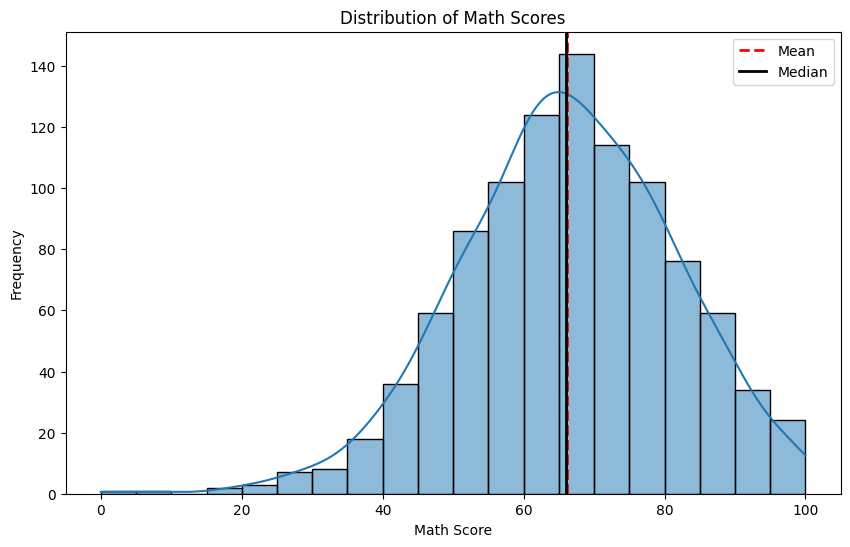

In [9]:
#Creating a histogram plot showing mean, median with a kde.
fig,ax = plt.subplots(figsize = (10,6) )
sns.histplot(data = df, x = 'math_score', kde = True ,bins =20 )
ax.axvline(df['math_score'].mean(), color = 'red', linestyle = 'dashed', linewidth = 2 , label = f'Mean')
ax.axvline(df['math_score'].median(), color = 'black', linewidth = 2 , label = f'Median')
ax.set_title('Distribution of Math Scores')
ax.set_xlabel('Math Score')
ax.set_ylabel('Frequency')
ax.legend()

### Q1: The mean and median are close to each other, which indicates that the distribution is approximately symmetric around it's center, also outliers have less effect on the mean . However this does not guarantee to indicate that the math_score is normally distributed.

###Q2: The math_score has a negative skewness( left tail) , also skewness = -0.28

###Q3 : Kurtosis = 0.275, which indicates a slightly heavier tails than a normal distribution. This suggests that extreme scores may occur somewhat more frequently, although the distribution's kurtosis is relatively close to that of a normal distribution.

Text(0.5, 0, 'Math Score')

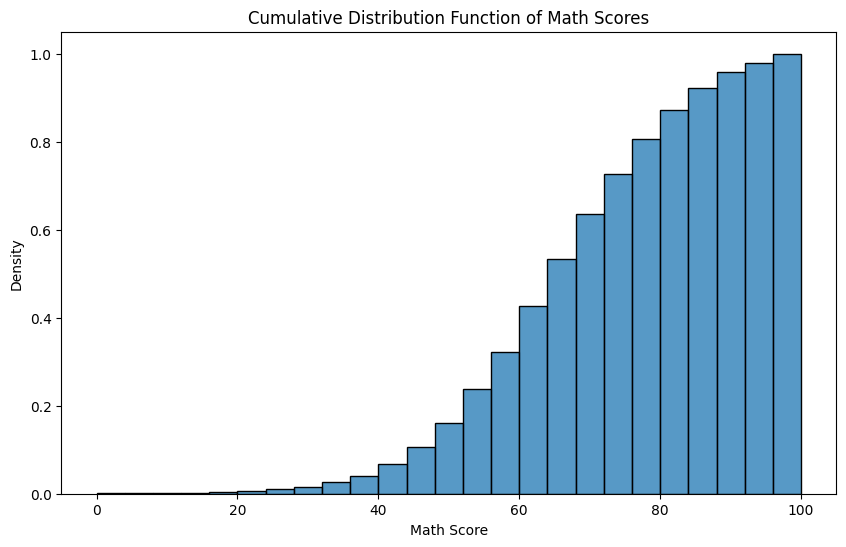

In [10]:
#Creating a CDF plot
from scipy.stats import norm
fig,ax = plt.subplots(figsize = (10,6))
sns.histplot(data = df , x = 'math_score' , cumulative =True , stat = 'density' )
ax.set_title('Cumulative Distribution Function of Math Scores')
ax.set_xlabel('Math Score')



In [11]:
# percentage of students score below 50

mean = df['math_score'].mean()
std = df['math_score'].std()

norm.cdf(50, loc=mean, scale=std)

np.float64(0.14433038476274984)

###Q4: The CDF shows the proportion of students who scored at or below a particular math score. for example the percentage of students scored below 50 is 14.43%

Text(0, 0.5, 'Math Score')

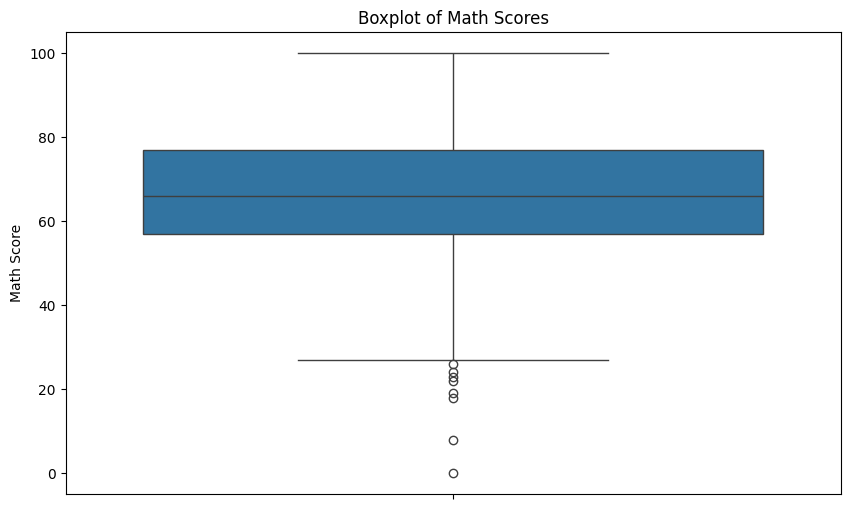

In [12]:
#Creating a Boxplot of math score
fig,ax =plt.subplots(figsize =(10,6))
sns.boxplot(data =df ,y ='math_score')
ax.set_title('Boxplot of Math Scores')
ax.set_ylabel('Math Score')


In [13]:
#Normality test
result =stats.normaltest(df['math_score'])
print(result)
print(result.pvalue < 0.05)

NormaltestResult(statistic=np.float64(15.408960513931822), pvalue=np.float64(0.00045080293869937836))
True


###The normality test produced a p-value of 0.000451, which is less than 0.05. Therefore the result is significant, which means  that the math scores significantly deviate from a normal distribution.

###Q5: Although the math scores appear approximately bell-shaped and the mean and median are very close, the distribution shows slight negative skewness and slightly positive excess kurtosis. The normality test gives a p-value below 0.05, indicating that the scores deviate significantly from a normal distribution. Therefore, the distribution is roughly bell-shaped but not statistically normal.

##Univariate Analysis

Text(0, 0.5, 'Frequency')

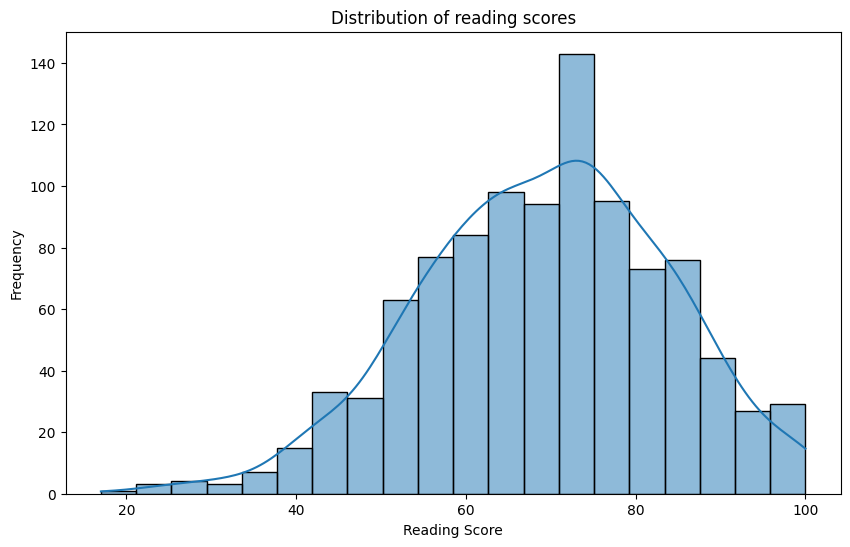

In [14]:
#Histogram- Reading score
fig,ax = plt.subplots(figsize = (10,6))
sns.histplot(data =df , x = 'reading_score' , kde =True , bins =20)
ax.set_title('Distribution of reading scores')
ax.set_xlabel('Reading Score')
ax.set_ylabel('Frequency')


Text(0, 0.5, 'Writing Scores')

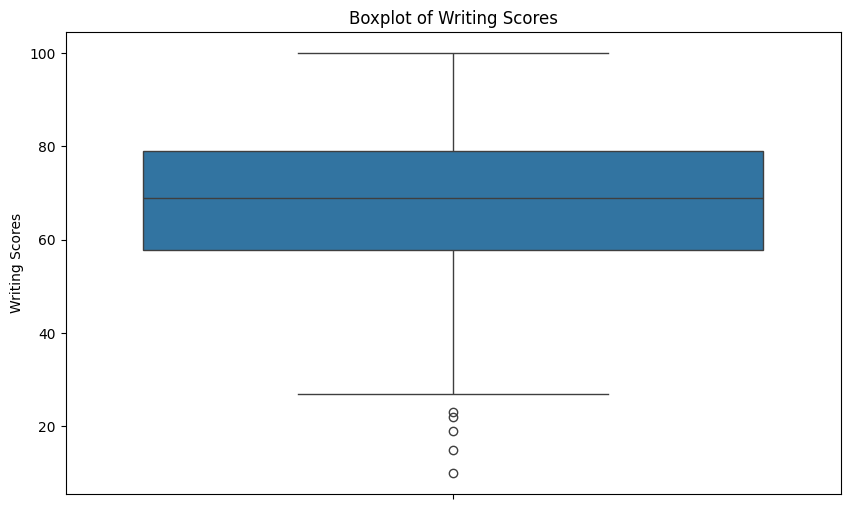

In [15]:
#Boxplot of Writing Score
fig,ax =plt.subplots(figsize =(10,6))
sns.boxplot(data=df , y ='writing_score')
ax.set_title('Boxplot of Writing Scores')
ax.set_ylabel('Writing Scores')


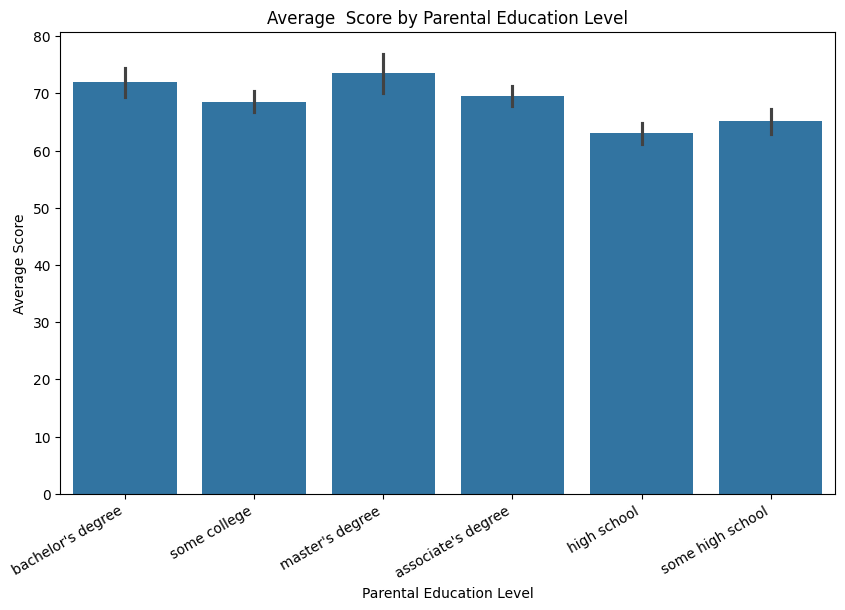

In [16]:
#Barplot of Parental Education Level
fig,ax = plt.subplots(figsize = (10,6))
sns.barplot(data=df, x='parental_level_of_education', y='average_score')

ax.set_title('Average  Score by Parental Education Level')
ax.set_xlabel('Parental Education Level')
ax.set_ylabel('Average Score')

plt.xticks(rotation=30, ha='right')

plt.show()

Text(0, 0.5, 'Count')

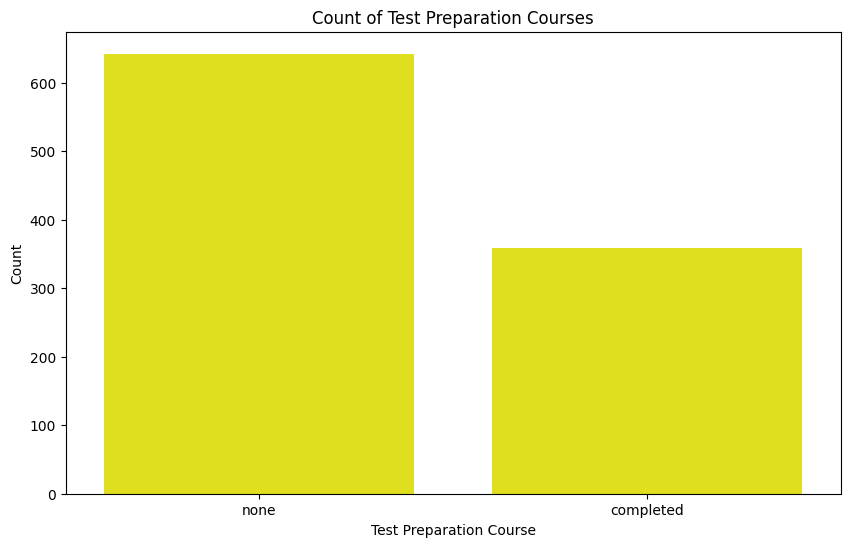

In [17]:
#Countplot of test preparation course
fig,ax = plt.subplots(figsize = (10,6))
sns.countplot(data =df , x = 'test_preparation_course', color='yellow' )
ax.set_title('Count of Test Preparation Courses')
ax.set_xlabel('Test Preparation Course')
ax.set_ylabel('Count')

####Answering the Analysis Questions
####Q1:Writing scores have the greatest variation, with a standard deviation of approximately 15.20, followed by math (15.16) and reading (14.60). However, the differences are relatively small, indicating that the three subjects have similar levels of score variability.

####Q2: There are 358 students, that have completed the preparation course.

####Q3: Some college is the most common one.

####Q4: The categorical variables are not equally balanced. Gender is relatively balanced, with 518 females and 482 males. However, other variables show noticeable differences. For example, Group C has 319 students compared to only 89 in Group A, while the master's degree category has only 59 students compared to 226 in the some college category. Additionally, standard lunch and no test preparation are more common than their alternatives. Overall, some categories are considerably smaller than others.

##Multivariate Analysis

##Conclusions